In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress


In [2]:
data = pd.read_csv("données/LucasBenjamin_684432bf9acc38d54321fc04.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,72492.0,external-consent.html,external-html,72692,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,78581,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,12150.0,NaN,survey-dropdown,90750,0.0-2.0,NaN,"{""0"":""18-25"",""1"":""M""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,17536.0,NaN,survey-text,108295,0.0-3.0,NaN,"{""Q0"":""684432bf9acc38d54321fc04""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,56654.0,NaN,instructions,164950,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":12674},{""page_...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
335,NaN,NaN,lb-SeqAns-visual,3158925,0.0-224.0,NaN,NaN,NaN,2167.0,NaN,Stims/Gabor_img/Gabor_0.png,"8.4713010053,-6.9664267772,-28.9437046841,14.4...","0,45,45,0,0,45,0",NaN,228.221040,0.0,25.791335,4.0,NaN
336,NaN,NaN,lb-SeqAns-visual,3170618,0.0-225.0,NaN,NaN,NaN,2620.0,NaN,Stims/Gabor_img/Gabor_0.png,"241.6571528293,116.9351700295,98.025899629,182...","-45,45,45,0,45",NaN,233.664135,0.0,176.498556,0.0,NaN
337,NaN,NaN,lb-SeqAns-visual,3176301,0.0-226.0,NaN,NaN,NaN,2659.0,NaN,Stims/Gabor_img/Gabor_0.png,92.0353409512,45,NaN,196.410785,0.0,137.035341,0.0,NaN


## Fonctions

In [3]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, a[i]))
    return(np.angle(resulting_vector))

In [4]:
def Angle_moyen_circulaire(angle_list_rad):
    rad_doubled = 2 * angle_list_rad                         # ×2 AVANT
    mean_doubled = CircularMean(rad_doubled)                 # TA fonction (rad)
    mean_ori_rad = mean_doubled / 2                          # ÷2 APRÈS
    return mean_ori_rad                               

In [5]:
def circular_error(a, b):
    return ((a - b + np.pi/2) % np.pi) - np.pi/2   # équivalent de [-90°, +90°]

def circular_error_deg(a, b):
    return ((a - b + 180/2) % 180) - 180/2   # équivalent de [-90°, +90°]

In [6]:
# norme du vecteur moyen circulaire pour des orientations. Retourne une valeur entre 0 et 1
# Proche de 1 = angles très proches, proche de 0 = angles très dispersés

def confiance (angle_list_rad) :
    if len(angle_list_rad)==0:
        return(np.nan)
    doubled = 2*angle_list_rad
    resultant = 0 
    for theta in doubled:
        if not np.isnan(theta):
            resultant += cmath.exp(complex(0, theta))
    return abs(resultant) / len(angle_list_rad)

## Filtering du dataframe pour 1 sujet

### dataframe en degré

In [7]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)
df_filtered["expected_targets"] = df_filtered['expected_angles'].apply(np.mean) # the best they could have done with what they were given


df_filtered = df_filtered.dropna(subset=["final_angle"])

### dataframe en radian

In [8]:
df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "target", "expected_angles", "expected_targets", "stimulus_rotations"])
df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])

df_radian['target'] = np.deg2rad(df_filtered['target'])
df_radian['expected_targets'] = np.deg2rad(df_filtered['expected_targets'])

df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian["rad_target_expected"] = df_radian["expected_angles"].apply(Angle_moyen_circulaire) # moyenne circulaire des angles attendus 
df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 

df_radian

,trial_rt,score,length of sequence,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,mean_rotation
0,2428.0,8,7,2.298566,2.167915,2.168025,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[1.148981365499507, 2.329885149108054, 2.70502...","[1.9343795288969552, 2.329885149108054, 1.9196...",-0.974011,-0.112200
1,3402.0,10,5,3.141593,0.052623,3.193430,"[0.0, 0.7853981633974483, 0.0, -0.785398163397...","[2.6976008517068717, 2.2843827503684624, 3.116...","[2.6976008517068717, 3.0697809137659107, 3.116...",0.055244,0.157080
2,4862.0,6,1,1.681454,1.385806,1.385806,[-0.7853981633974483],[2.171204662540556],[1.3858064991431076],1.385806,-0.785398
3,2565.0,10,1,2.472138,2.454566,2.454566,[0.0],[2.454565798814005],[2.454565798814005],-0.687027,0.000000
4,2406.0,0,7,2.356194,1.181008,1.194297,"[-0.7853981633974483, 0.0, -0.7853981633974483...","[2.8250856932357697, 1.5463560211231628, 1.801...","[2.0396875298383215, 1.5463560211231628, 1.016...",1.133615,-0.112200
...,...,...,...,...,...,...,...,...,...,...,...
195,2167.0,4,7,3.983209,0.450144,0.453019,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[0.14785209446999062, -0.12158708436123743, -0...","[0.14785209446999062, 0.6638110790362108, 0.28...",0.440748,0.336599
196,2620.0,0,5,4.078209,3.080481,3.076384,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[4.217712977866415, 2.0409037283941696, 1.7108...","[3.4323148144689672, 2.8263018917916183, 2.496...",-0.046250,0.314159
197,2659.0,0,1,3.428015,2.391718,2.391718,[0.7853981633974483],[1.6063197277940098],[2.3917178911914583],-0.749875,0.785398
198,1894.0,10,7,2.265535,2.226448,2.231322,"[0.0, 0.7853981633974483, -0.7853981633974483,...","[2.859158212075561, 1.1540872860958609, 3.3071...","[2.859158212075561, 1.9394854494933091, 2.5217...",-0.931541,-0.112200


### dataframes pour tous les participants

In [9]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def all_participants (dfs) :
    # delete useless columns and rows
    df_radian = dfs[dfs["stimulus_rotations"].notna()]
    df_radian = df_radian.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
    df_radian.reset_index(drop=True, inplace=True)
    df_radian["length of sequence"] = df_radian["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
    
    # everything in float/int
    df_radian['presented_angles'] = df_radian['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_radian['stimulus_rotations'] = df_radian['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_radian['score'] = df_radian['score'].astype(int)
    
    # new columns 
    df_radian["expected_angles"] = df_radian.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)
    df_radian["expected_targets"] = df_radian['expected_angles'].apply(np.mean)
    
    # Apply radian conversion to every angles
    df_radian['final_angle'] = df_radian['final_angle'].apply(np.deg2rad)
    df_radian['target'] = df_radian['target'].apply(np.deg2rad)
    df_radian['presented_angles'] = df_radian['presented_angles'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))
    df_radian['stimulus_rotations'] = df_radian['stimulus_rotations'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))    
    df_radian['expected_angles'] = df_radian['expected_angles'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))    
    df_radian['expected_targets'] = df_radian['expected_targets'].apply(np.deg2rad)
    
    df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["expected_targets"]) # erreur par rapport à l'angle théorique
    df_radian["dict_angle_to_rotation"]= df_radian.apply(lambda row: dict(zip(row["presented_angles"], row["stimulus_rotations"])), axis=1) 
    df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(Angle_moyen_circulaire)
    df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  
    df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean)
    

    mean_rt = df_radian["trial_rt"].mean()
    std_rt = df_radian["trial_rt"].std()
    upper_threshold = mean_rt + 5*std_rt

    rt_filtered = df_radian["trial_rt"].copy()
    rt_filtered[(rt_filtered > upper_threshold)] = np.nan
    df_radian["rt_filtered"] = rt_filtered
    return df_radian

## Performances

### Est ce que les participants ont bien répondu ? (erreur entre angle tiré et la target) 

+ ajouter la confiance pour voir la distribution de la confiance pour les angles expected 

In [10]:
df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["expected_targets"]) # erreur par rapport à l'angle théorique
df_filtered["error_to_target"] = circular_error_deg(df_filtered["final_angle"], df_filtered["expected_targets"]) # erreur par rapport à l'angle théorique

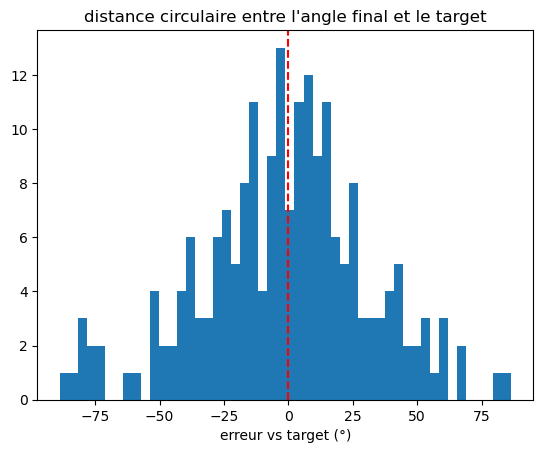

In [11]:
plt.hist(np.rad2deg(df_radian["error_to_target"]), bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et le target")
plt.show()

### Est ce que les participants ignorent les rotations ? (ne prennent pas en compte les couleurs, seulement les orientations qu'ils voient)

In [15]:
df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(Angle_moyen_circulaire)
df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  

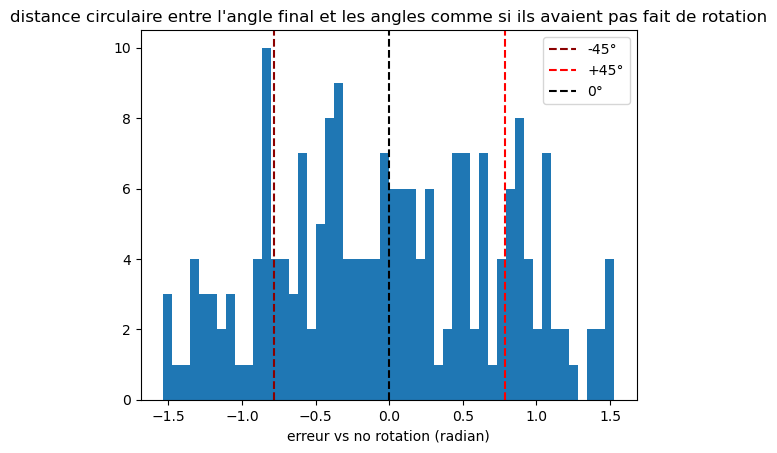

In [16]:
plt.hist(df_radian["error_wo_rotation"], bins=50)
plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(np.deg2rad(0), color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs no rotation (radian)")
plt.title("distance circulaire entre l'angle final et les angles comme si ils avaient pas fait de rotation")
plt.legend()
plt.show()

### rotation moyenne vs erreur

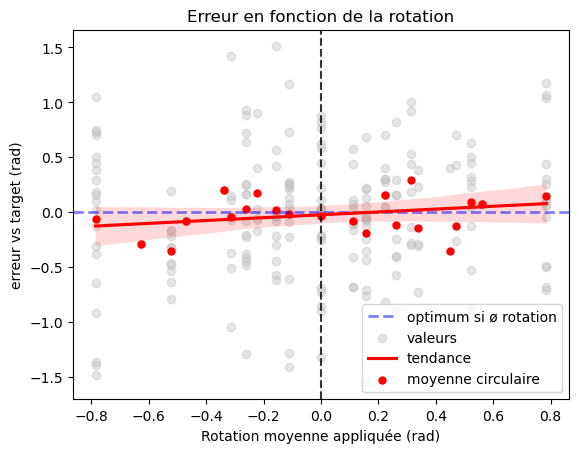

In [18]:
x = (df_radian.groupby("mean_rotation")["error_to_target"].apply(np.mean).reset_index().sort_values("mean_rotation"))

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum si ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x="mean_rotation", y="error_to_target", data=df_radian, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
plt.scatter(x["mean_rotation"], x["error_to_target"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("erreur vs target (rad)")
plt.title("Erreur en fonction de la rotation")
plt.legend()
plt.show()

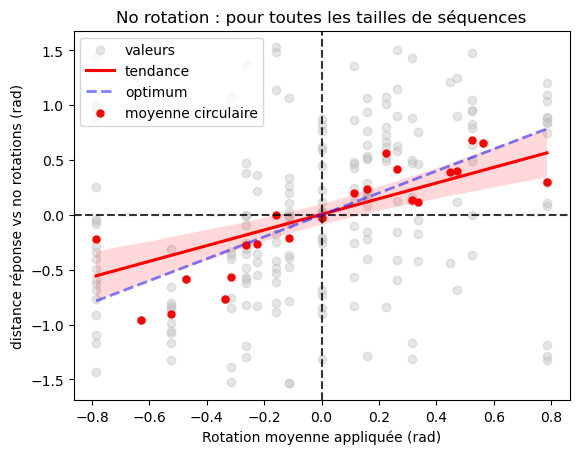

In [19]:
x = (df_radian.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))


plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_radian, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
borne = x["mean_rotation"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("distance réponse vs no rotations (rad)")
plt.title("No rotation : pour toutes les tailles de séquences")
plt.legend()
plt.show()

plot pour différentes tailles de séquences

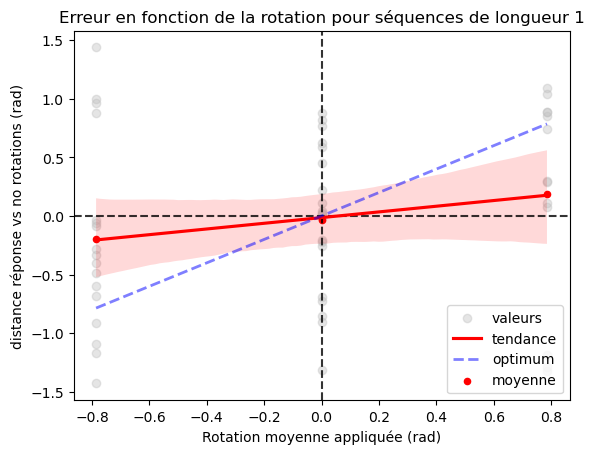

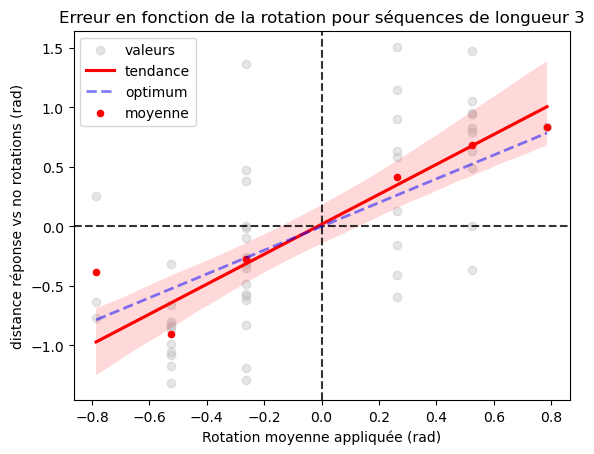

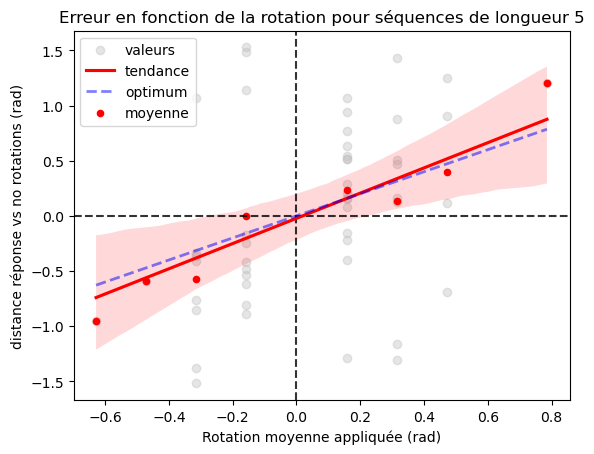

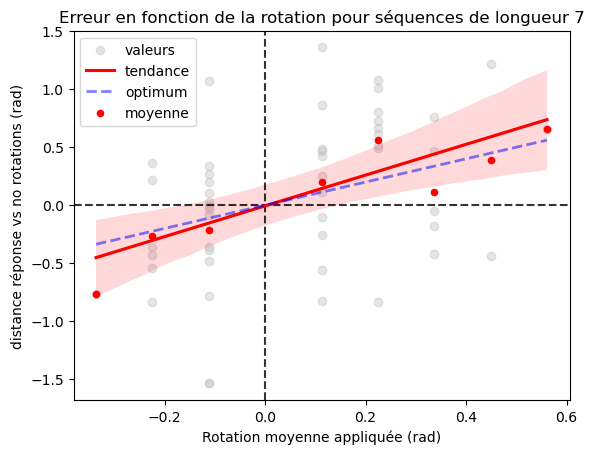

In [20]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation"]
    sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_radian[df_radian["length of sequence"]==seqlen], color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=20, label="moyenne")

    plt.xlabel("Rotation moyenne appliquée (rad)")
    plt.ylabel("distance réponse vs no rotations (rad)")
    plt.title(f"Erreur en fonction de la rotation pour séquences de longueur {seqlen}")
    plt.legend()
    plt.show()

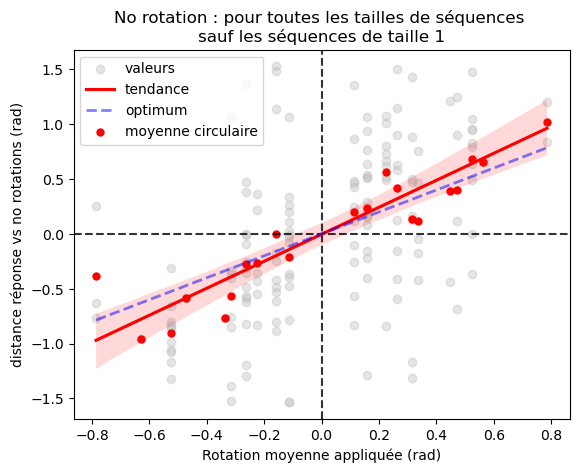

In [21]:
df = df_radian[df_radian["length of sequence"]!=1]

x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

borne = x["mean_rotation"]
sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("distance réponse vs no rotations (rad)")
plt.title("No rotation : pour toutes les tailles de séquences \nsauf les séquences de taille 1")
plt.legend()
plt.show()

## Reaction time et confiance

### RT vs erreur

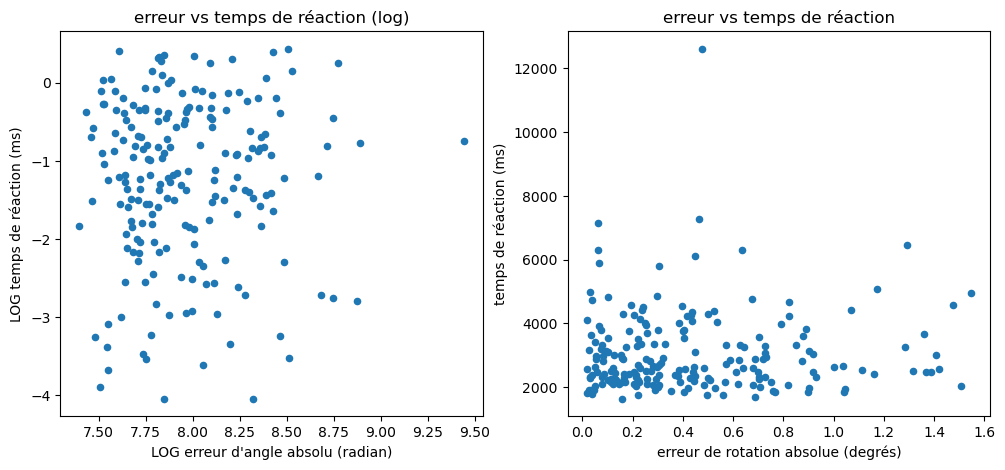

In [22]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.scatter(df_radian["trial_rt"].apply(np.log), np.abs(df_radian["error_to_target"]).apply(np.log), s=20)
plt.xlabel("LOG erreur d'angle absolu (radian)")
plt.ylabel("LOG temps de réaction (ms)")
plt.title("erreur vs temps de réaction (log)")

plt.subplot(1,2,2) 
plt.scatter(np.abs(df_radian["error_to_target"]), df_radian["trial_rt"], s=20)
plt.xlabel("erreur de rotation absolue (degrés)")
plt.ylabel("temps de réaction (ms)")
plt.title("erreur vs temps de réaction")
plt.show()

erreur vs le temps

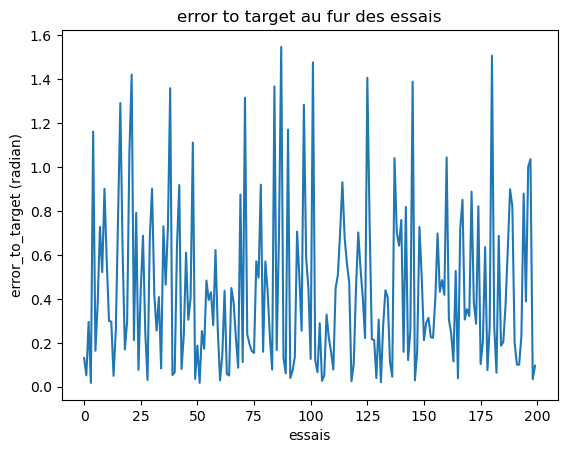

In [23]:
plt.plot(np.abs(df_radian["error_to_target"]))
plt.xlabel("essais")
plt.ylabel("error_to_target (radian)")
plt.title("error to target au fur des essais")
plt.show()

### RT vs temps

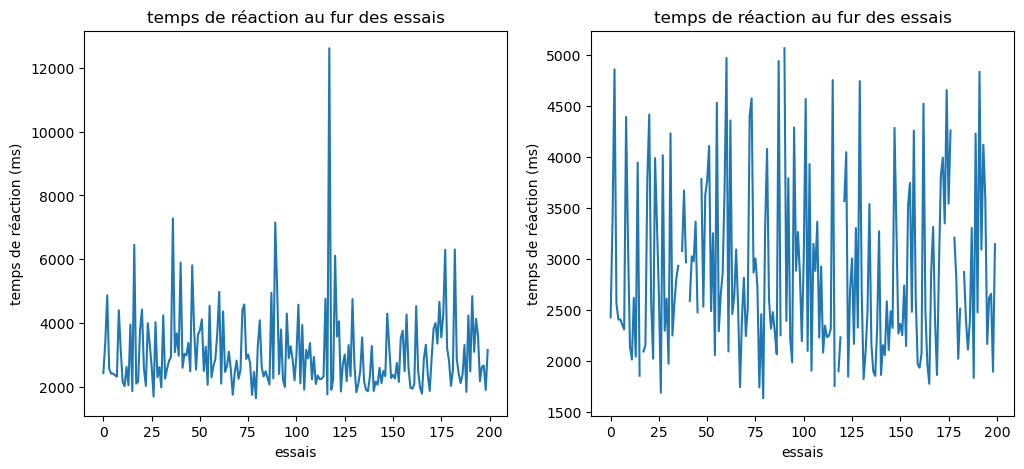

In [24]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(np.abs(df_radian["trial_rt"]))
plt.xlabel("essais")
plt.ylabel("temps de réaction (ms)")
plt.title("temps de réaction au fur des essais")

mean_rt = df_radian["trial_rt"].mean()
std_rt = df_radian["trial_rt"].std()
upper_threshold = mean_rt + 2*std_rt

rt_filtered = df_radian["trial_rt"].copy()
rt_filtered[(rt_filtered > upper_threshold)] = np.nan

plt.subplot(1,2,2)
plt.plot(rt_filtered)
plt.xlabel("essais")
plt.ylabel("temps de réaction (ms)")
plt.title("temps de réaction au fur des essais")
plt.show()

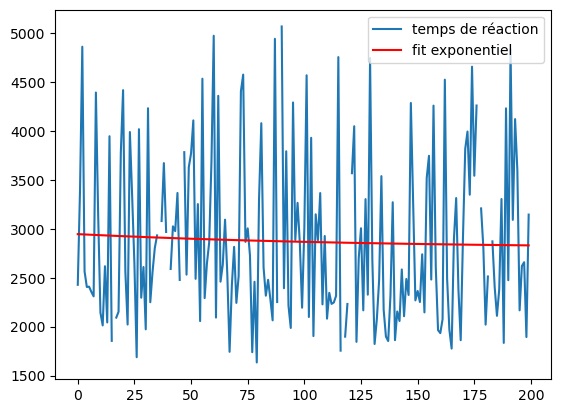

In [25]:
from scipy.optimize import curve_fit
import numpy as np

y = rt_filtered.values.astype(float)
x = np.arange(len(y))

# enlever NaN et inf
mask = np.isfinite(y)
x_clean = x[mask]
y_clean = y[mask]

# modèle exponentiel
def exp_model(x, a, b, c):
    return a * np.exp(-b * x) + c

# fit
params, _ = curve_fit(
    exp_model,
    x_clean,
    y_clean,
    p0=[1000, 0.01, 2000],   # meilleurs guess
    maxfev=10000             # évite erreur convergence
)

a, b, c = params

# prédiction sur toute la courbe
y_fit_full = exp_model(x, a, b, c)

plt.plot(x, y, label="temps de réaction")
plt.plot(x, y_fit_full, "r", label="fit exponentiel")
plt.legend()
plt.show()

## modèle de simulation

In [34]:
def optimal_model (list_presented_angles, list_perceived_colors) : 
    
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_perceived_colors) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of colors presented (length = {len(list_perceived_colors)}) don't have the same length")
        return None
    
    # color mapping : each color viewed equals to an angle
    if type(list_perceived_colors[0]) == str : # if list is the colors
        color_mapping_degrees = {"green" : np.deg2rad(45), "red" : np.deg2rad(-45), "grey" : np.deg2rad(0)}
        rotations_to_apply = [color_mapping_degrees[x] for x in list_perceived_colors] # les rotations à appliquer
    else : 
        rotations_to_apply = list_perceived_colors


    corrected_angles = np.array(list_presented_angles) + np.array(rotations_to_apply)

    target = Angle_moyen_circulaire(corrected_angles)

    return target

In [38]:
df_radian.iloc[0]

trial_rt                                                             2428.0
score                                                                     8
length of sequence                                                        7
final_angle                                                        2.298566
target                                                             2.167915
expected_targets                                                   2.168025
stimulus_rotations        [0.7853981633974483, 0.0, -0.7853981633974483,...
presented_angles          [1.148981365499507, 2.329885149108054, 2.70502...
expected_angles           [1.9343795288969552, 2.329885149108054, 1.9196...
rad_target_expected                                               -0.974011
mean_rotation                                                       -0.1122
error_to_target                                                    0.130541
dict_angle_to_rotation    {1.148981365499507: 0.7853981633974483, 2.3298...
angles_sans_

In [57]:
list_presented_angles = df_radian["presented_angles"].iloc[0] 
list_perceived_colors = df_radian["stimulus_rotations"].iloc[0]
x = optimal_model(list_presented_angles,list_perceived_colors)

if round(x%np.pi,3) == round(df_radian["expected_targets"].iloc[0], 3) :
    print("TRUE")
    print(x%np.pi, df_radian["expected_targets"].iloc[0])
else : 
    print("FALSE", x%np.pi, df_radian["expected_targets"].iloc[0])
    


TRUE
2.16758177668523 2.1680245677987515
